# Transition networks Fig 3 B&E

Directed and undirected networks & transition frequencies. 


In [8]:
# Data handling
import os
import re
import csv
import warnings
import itertools as it

import numpy as np
import pandas as pd
from tqdm import tqdm

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.patches import FancyArrowPatch

# Networks and statistical tests
import networkx as nx
from scipy.stats import binomtest, chi2_contingency, chisquare
import statsmodels.stats.multitest as stm

# Functions stored in a1_helpers.py
from a1_helpers import (
    get_time_taken_sec,
    extract_strategies,
    get_percentages,
    parse_values,
    directed_to_undirected_with_summed_weights,
    graph_primer,
    create_dic,
    percentage_scaler,
    get_transition_df,
    Euclidean_Dist,
)

# Progress bars for pandas
tqdm.pandas()

# Hide deprecation warnings
import warnings
warnings.filterwarnings("ignore")

In [9]:
from pathlib import Path

# Run with the notebook's Analysis folder as the working directory.
assert Path('a1_helpers.py').is_file(), 'Set the working directory to the Analysis folder.'
fig_folder = '../Figure_paper/'
Path(fig_folder).mkdir(parents=True, exist_ok=True)
colors = ['#0033ff', '#ff4ff1']

In [10]:
sequence_df = pd.read_csv('../Combined_data/seq_df_2025.csv', index_col=0)
sequence_df['game'] = sequence_df['experiment'].str[-1]

Review note: original graph weighting and exploratory transition tests are retained. Directed plots normalize weights twice, and chi-square calls use percentages. These require analytical review; splitting the notebook does not validate them.

In [11]:
# access the conditions data
all_conditions = pd.read_csv('../Combined_data/'+'all_conditions.csv',index_col = 0)

In [12]:
all_conditions['node'] = all_conditions['node'].replace({1: 'N_1', 2: 'N_2', 3: 'N_3',  4: 'N_4', 5: 'N_5', 
                                                         6: 'N_6', 
                                                         7: 'N_7', 
                                                         8: 'N_8', 
                                                         9: 'N_9', 
                                                         10: 'N_10'})
all_conditions.node.unique()

array(['N_1', 'N_2', 'N_3', 'N_4', 'N_5', 'N_6', 'N_7', 'N_8', 'N_9',
       'N_10'], dtype=object)

In [13]:
original_dict = {1: 'Node_1', 2: 'Node_2', 3: 'Node_3',  4: 'N_4', 5: 'N_5', 
                                                         6: 'N_6', 
                                                         7: 'N_7', 
                                                         8: 'N_8', 
                                                         9: 'N_9', 
                                                         10: 'N_10'}

inverted_dict = {v: k for k, v in original_dict.items()}

In [14]:
sequence_df['Node_ID']= sequence_df.Node_name.replace({'Node_1': 'N_1',
                                             'Node_2': 'N_2', 
                                             'Node_3': 'N_3',  
                                             'Node_4': 'N_4',
                                            'Node_5': 'N_5', 
                                                         'Node_6': 'N_6', 
                                                         'Node_7': 'N_7', 
                                                         'Node_8': 'N_8', 
                                                         'Node_9': 'N_9', 
                                                         'Node_10': 'N_10',
                                                         'hive' : 'N_1'})

Directed graph :

In [15]:
# Network figure rendering disabled; transition calculations remain active.
# fig, axes= plt.subplots(nrows=2,ncols=5,figsize = (15,7))
ind_nb = len(sequence_df.ppid.unique())

norm = Normalize(vmin=0, vmax=100)
cmap = cm.get_cmap('viridis',100)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
color= '#198ba3'

for col,scale in enumerate(['S1', 'S2', 'S3', 'S4', 'S5']):

    data_scale = sequence_df.loc[sequence_df.scale == scale]

    for row,condition in enumerate(['C1','C2']):
        data_conf =  data_scale.loc[data_scale.cond == condition]
        # ax = axes[row, col]
        ax = None  # graph_primer does not use the plotting axis.
        
        pos_chest,chests = create_dic(all_conditions,condition,scale)
        chests = chests[:-1]
        
        DG,edges,weights,node_sizes,edges_nozero,G_nozero,weights_nozero = graph_primer(chests,data_conf,ax, sortby=['ppid','trial_num'], sizing=10)
        
        weight_plot = tuple()
        
        w_list = list(weights_nozero)
    
        w_list = percentage_scaler(w_list)
        A = data_conf.groupby(['ppid','trial_num']).ngroups
        w_perc = [(w * 100) / A for w in w_list]  # Scale weights to 0-100
        for x in w_perc:
            
            x = x/20
            weight_plot += (x, )

        #Normalize the weights for color scaling

        edge_colors = [sm.to_rgba(w) for w in w_perc]

        # edges = nx.draw_networkx_edges(G_nozero, pos_chest, edgelist = edges_nozero,edge_color= "k",
        #            arrowstyle='-|>',width=list(weight_plot),
        #            connectionstyle='arc3, rad = 0.11',ax=ax)

        subnodelist = sequence_df.Node_ID.dropna().unique()
        labels = {k:k for k in subnodelist}   
        
        node_sizes = [j-j +50 for j in node_sizes]
        mapping = inverted_dict

        H       = nx.relabel_nodes(DG, mapping, copy=True)  

        
        # nodes   = nx.draw_networkx_nodes(DG, pos_chest, node_size = node_sizes, node_color = color, edgecolors='w', alpha=.8,ax=ax)

        connectionstyle = [f"arc3,rad={r}" for r in it.accumulate([0.15] * 4)]

        # nx.draw_networkx_labels(DG,pos_chest, labels=labels ,font_size=9, font_family='sans-serif',ax=ax,font_color='black')
        

        # ax.set_aspect('equal')

        # ax.title.set_position([0.5, 1.1])
        # ax.title.set_text('{}-{}'.format(condition,scale))
        # ax.axis('off')

# fig.tight_layout()


undirected graph

In [16]:
# Network figure rendering disabled; transition calculations remain active.
# fig, axes= plt.subplots(nrows=2,ncols=5,figsize = (15,7))

DF        = sequence_df
ind_nb    = len(sequence_df.ppid.unique())
All_trans = pd.DataFrame()

# Normalize edge weights for consistent colormap scaling
norm  = Normalize(vmin=0, vmax=100)
cmap  = cm.get_cmap('viridis',100)
sm    = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
color = '#198ba3'
images =[]

for col,scale in enumerate(['S1', 'S2', 'S3', 'S4', 'S5']):

    data_scale = DF.loc[DF.scale == scale]

    for row,condition in enumerate(['C1','C2']):

        data_conf =  data_scale.loc[data_scale.cond == condition]
        # ax = axes[row, col]
        ax = None  # graph_primer does not use the plotting axis.
        
        pos_chest,chests = create_dic(all_conditions,condition,scale)
        chests = chests[:-1]
        
        DG,edges,weights,node_sizes,edges_nozero,G_nozero,weights_nozero = graph_primer(chests,data_conf,ax, sortby=['ppid','trial_num'],bi = False, sizing=10)
        
        weight_plot = tuple()
        
        w_list = list(weights_nozero)

        A = data_conf.groupby(['ppid','trial_num']).ngroups

        
        w_perc = [(w * 100) / A for w in w_list]  # Scale weights to 0-100
        for x in w_perc:
            
            x = x/20
            weight_plot += (x, )


        edge_colors = [sm.to_rgba(w) for w in w_perc]

        # Draw edges without direction (undirected graph)
        # edges = nx.draw_networkx_edges(DG, pos_chest, edgelist = edges_nozero, edge_color= edge_colors,
        #                             width=list(weight_plot), ax=ax)
        # Draw edge weight labels
        bbox_props = dict(boxstyle="DArrow,pad=0.3", alpha = 0, ec="b", lw=2)

        edge_labels = {edge: f"{weight:.2f}" for edge, weight in zip(edges_nozero, w_perc)}
        # nx.draw_networkx_edge_labels(DG, pos_chest, edge_labels = edge_labels, font_size=8, ax=ax,bbox=bbox_props)

        ## Nodes 
        subnodelist = sequence_df.Node_ID.dropna().unique()
        labels = {k:k for k in subnodelist}  
        # Draw the nodes
        # nodes = nx.draw_networkx_nodes(DG, pos_chest, node_size=50, node_color=color, edgecolors='w', alpha=0.8, ax=ax)

        # Draw labels node
        # g = nx.draw_networkx_labels(DG, pos_chest, labels={k: v for k, v in labels.items() if k in pos_chest},
        #                         font_size=9, font_family='sans-serif', ax=ax, font_color='black')
        
    
        # ax.set_aspect('equal')
        # ax.title.set_position([0.5, 1.1])
        # ax.title.set_text('{}-{}'.format(condition, scale))
        # ax.axis('off')
        df_edge = nx.to_pandas_edgelist(DG, nodelist=chests)
        df_edge['w_perc'] = df_edge['weight']*100/A
        df_edge['cond']   = condition
        df_edge['scale']  = scale
        #degree_centrality = nx.centrality.degree_centrality(DG)  # save results in a variable to use again
        #print(degree_centrality)

        All_trans = pd.concat([All_trans,df_edge],axis= 0,ignore_index = True)
        
  


# Create the colorbar for the legend
# fig.tight_layout()

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # This is a hack to make the colorbar work properly
# plt.savefig(fig_folder+'Fig3_Graph_network_original.png')
# plt.savefig(fig_folder+'Fig3_Graph_network_original.svg')
# fig.colorbar(sm, ax=axes, orientation='vertical', label='prevalence of transitions (%) per configurations')


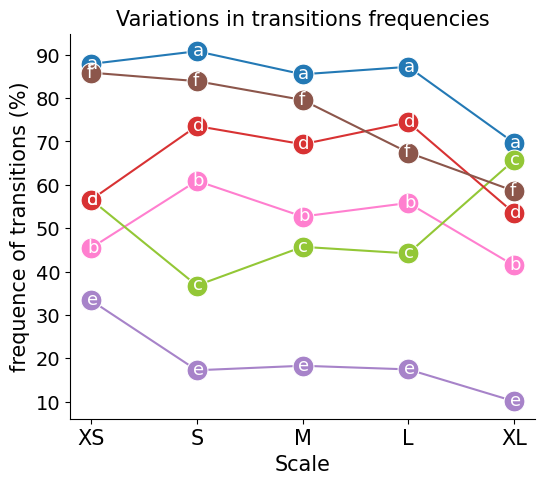

In [17]:
All_trans['transition'] = All_trans.apply(lambda x: f"{x['source']}_{x['target']}", axis=1)

C2_trans  = All_trans.loc[All_trans.cond == 'C2']
C2_trans.groupby('transition')['w_perc'].std().describe()
q90 = C2_trans.groupby('transition')['w_perc'].std().quantile(0.90)
mask = C2_trans.groupby('transition')['w_perc'].std() < q90
plt.figure(figsize =(6,5))
# Filter out rows where the variance is greater than 20
C2_trans = C2_trans[~C2_trans['transition'].isin(mask[mask].index)]
C2_trans['label'] = C2_trans['transition'].map({'N_1_N_10' : 'a',
                                         'N_2_N_3' : 'b',
                                         'N_2_N_4' : 'c',
                                         'N_3_N_4' : 'd',
                                         'N_3_N_6' : 'e',
                                         'N_4_N_5' : 'f'})

C2_trans['scale_num'] = C2_trans['scale'].map({'S1' : 1,
                                         'S2' : 2,
                                         'S3' : 3,
                                         'S4' : 4,
                                         'S5' : 5})

sns.lineplot(data = C2_trans, x = 'scale_num', y = 'w_perc',hue = 'label',legend = True,marker  ='o',markeredgecolor = "w",
             markersize = 15, palette= ['#2379b5','#ff7fcf','#93c736','#d83233','#a783c9','#8c564b'],zorder = 0)
ax = plt.gca()
for item in C2_trans.groupby('label'):
    #item[1] is a grouped data frame
    for x,y,m in item[1][['scale_num','w_perc','label']].values:
        
        ax.text(x-0.04,y-1,m,color='w',fontsize = 13,zorder = 100)

plt.ylabel('frequence of transitions (%)',fontsize= 15)
plt.xlabel('Scale',fontsize= 15)
plt.title('Variations in transitions frequencies',fontsize= 15)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=10)
sns.despine()
ax.get_legend().remove()
ax.set_xticks([1,2, 3,4,5], ['XS', 'S', 'M','L','XL'],fontsize= 15)
plt.savefig(fig_folder+'Fig4_C2_trans_original.png')
plt.savefig(fig_folder+'Fig4_C2_trans_original.svg')

In [18]:
for trans,df in C2_trans.groupby('transition'):
    print(trans)
    print(chisquare(df.w_perc.values))

N_1_N_10
Power_divergenceResult(statistic=np.float64(3.3034043225753646), pvalue=np.float64(0.5083930538743849))
N_2_N_3
Power_divergenceResult(statistic=np.float64(4.8134683541018095), pvalue=np.float64(0.3069777332973014))
N_2_N_4
Power_divergenceResult(statistic=np.float64(10.346309194747423), pvalue=np.float64(0.034981196309854856))
N_3_N_4
Power_divergenceResult(statistic=np.float64(5.839145809380721), pvalue=np.float64(0.21148732535122539))
N_3_N_6
Power_divergenceResult(statistic=np.float64(15.056752925089814), pvalue=np.float64(0.004584943703297607))
N_4_N_5
Power_divergenceResult(statistic=np.float64(7.255207092514103), pvalue=np.float64(0.12300080182146511))


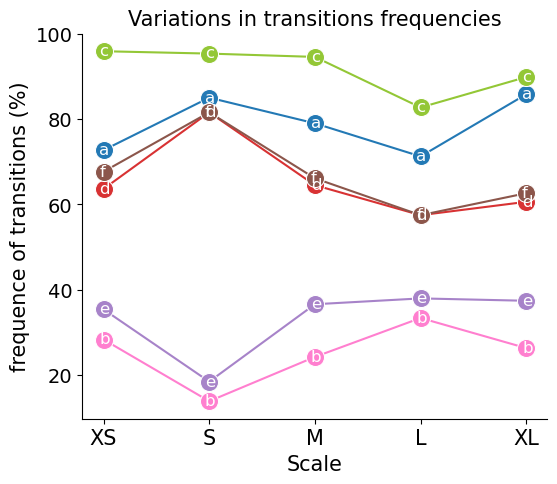

In [19]:
All_trans['transition'] = All_trans.apply(lambda x: f"{x['source']}_{x['target']}", axis=1)

C1_trans  = All_trans.loc[All_trans.cond == 'C1']
C1_trans.groupby('transition')['w_perc'].std().describe()
q90 = C1_trans.groupby('transition')['w_perc'].std().quantile(0.90)
mask = C1_trans.groupby('transition')['w_perc'].std() < q90
plt.figure(figsize =(6,5))
# Filter out rows where the variance is greater than 20
C1_trans = C1_trans[~C1_trans['transition'].isin(mask[mask].index)]
C1_trans['label'] = C1_trans['transition'].map({'N_5_N_6' : 'a',
                                         'N_5_N_8' : 'b',
                                         'N_6_N_7' : 'c',
                                         'N_7_N_8' : 'd',
                                         'N_7_N_9' : 'e',
                                         'N_8_N_9' : 'f'})

C1_trans['scale_num'] = C1_trans['scale'].map({'S1' : 1,
                                         'S2' : 2,
                                         'S3' : 3,
                                         'S4' : 4,
                                         'S5' : 5})

sns.lineplot(data = C1_trans, x = 'scale_num', y = 'w_perc',hue = 'label',legend = True,marker  ='o',markeredgecolor = "w",
             markersize = 13, palette= ['#2379b5','#ff7fcf','#93c736','#d83233','#a783c9','#8c564b'],zorder = 0)
ax = plt.gca()
for item in C1_trans.groupby('label'):
    #item[1] is a grouped data frame
    for x,y,m in item[1][['scale_num','w_perc','label']].values:
        
        ax.text(x-0.04,y-1,m,color='w',fontsize = 12,zorder = 100)

plt.ylabel('frequence of transitions (%)',fontsize= 15)
plt.xlabel('Scale',fontsize= 15)
plt.title('Variations in transitions frequencies',fontsize= 15)
ax.tick_params(axis='both', which='major', labelsize=14)
ax.tick_params(axis='both', which='minor', labelsize=10)
sns.despine()
ax.get_legend().remove()
ax.set_xticks([1,2, 3,4,5], ['XS', 'S', 'M','L','XL'],fontsize= 15)
plt.savefig(fig_folder+'Fig4_C1_trans_original.png')
plt.savefig(fig_folder+'Fig4_C1_trans_original.svg')

In [20]:
for trans,df in C1_trans.groupby('transition'):
    print(trans)
    print(chisquare(df.w_perc.values))

N_5_N_6
Power_divergenceResult(statistic=np.float64(2.3188378073282405), pvalue=np.float64(0.6773414713447067))
N_5_N_8
Power_divergenceResult(statistic=np.float64(8.259246099463459), pvalue=np.float64(0.08253020983644599))
N_6_N_7
Power_divergenceResult(statistic=np.float64(1.347308225316971), pvalue=np.float64(0.853299409718252))
N_7_N_8
Power_divergenceResult(statistic=np.float64(5.373606522425658), pvalue=np.float64(0.2510649763298744))
N_7_N_9
Power_divergenceResult(statistic=np.float64(8.302903931763321), pvalue=np.float64(0.08109180623548634))
N_8_N_9
Power_divergenceResult(statistic=np.float64(4.836168749798302), pvalue=np.float64(0.30452438740130605))
